## Perform adversarial testing by slightly modifying input features using perturbation techniques, manually designing worst-case adversarial samples, and quantifying their impact on model robustness.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [10]:
df = pd.read_csv("heart.csv")
df = df.drop_duplicates().dropna().reset_index(drop=True)

X = df.drop(columns=["target"])
y = df["target"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

test_predictions = model.predict(X_test)
test_probabilities = model.predict_proba(X_test)

print("Test Accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Test Precision:", round(precision_score(y_test, test_predictions, zero_division=0), 4))
print("Test Recall:", round(recall_score(y_test, test_predictions, zero_division=0), 4))
print("Test F1 Score:", round(f1_score(y_test, test_predictions, zero_division=0), 4))

Test Accuracy: 0.7869
Test Precision: 0.75
Test Recall: 0.9091
Test F1 Score: 0.8219


In [11]:
rng = np.random.default_rng(42)

continuous_features = [
    col for col in ["age", "trestbps", "chol", "thalach", "oldpeak"]
    if col in X_train.columns
]

n_samples = max(100, len(X_test))

ood_samples = X_test.sample(
    n=n_samples,
    replace=n_samples > len(X_test),
    random_state=42
).reset_index(drop=True).copy()

for col in continuous_features:
    col_min = X_train[col].min()
    col_max = X_train[col].max()
    col_range = col_max - col_min

    direction = rng.choice([-1, 1], size=n_samples)
    shift = rng.uniform(0.15, 0.35, size=n_samples) * col_range

    ood_samples[col] = (
        ood_samples[col].to_numpy() + direction * shift
    ).clip(col_min - 0.25 * col_range, col_max + 0.25 * col_range)

print("Synthetic OOD samples:", ood_samples.shape)
display(ood_samples.head())

Synthetic OOD samples: (100, 13)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,39.880881,0,0,97.619017,346.324979,0,1,129.103110,0,1.427681,2,0,2
1,46.270678,1,2,176.502720,373.145088,0,0,144.690014,0,-1.550000,2,0,2
2,68.754474,1,0,83.484287,280.426205,0,0,69.899896,1,1.762800,1,1,2
3,40.417432,0,2,178.950627,126.150433,0,1,191.582831,0,1.224696,2,1,2
4,28.030412,0,2,136.195449,277.824760,0,1,144.037727,0,1.987449,1,0,2


In [12]:
ood_predictions = model.predict(ood_samples)
ood_probabilities = model.predict_proba(ood_samples)

normal_confidence = test_probabilities.max(axis=1)
ood_confidence = ood_probabilities.max(axis=1)

print("Normal Test Mean Confidence:", round(normal_confidence.mean(), 4))
print("OOD Mean Confidence:", round(ood_confidence.mean(), 4))

print("Normal Low Confidence Rate:", round(np.mean(normal_confidence < 0.60), 4))
print("OOD Low Confidence Rate:", round(np.mean(ood_confidence < 0.60), 4))

print("High Confidence OOD Samples:", int(np.sum(ood_confidence >= 0.90)))

Normal Test Mean Confidence: 0.7692
OOD Mean Confidence: 0.6982
Normal Low Confidence Rate: 0.082
OOD Low Confidence Rate: 0.24
High Confidence OOD Samples: 6


In [13]:
prediction_comparison = pd.DataFrame({
    "Normal_Test": pd.Series(test_predictions).value_counts(normalize=True),
    "Synthetic_OOD": pd.Series(ood_predictions).value_counts(normalize=True)
}).fillna(0)

print(prediction_comparison.round(4))

   Normal_Test  Synthetic_OOD
1       0.6557           0.62
0       0.3443           0.38


In [14]:
range_checks = []

for col in continuous_features:
    lower = X_train[col].min()
    upper = X_train[col].max()

    outside = (ood_samples[col] < lower) | (ood_samples[col] > upper)

    range_checks.append({
        "Feature": col,
        "Values_Outside_Training_Range": int(outside.sum()),
        "Percentage_Outside_Range": round(outside.mean() * 100, 2)
    })

range_check_df = pd.DataFrame(range_checks)
display(range_check_df)

,Feature,Values_Outside_Training_Range,Percentage_Outside_Range
0,age,7,7.0
1,trestbps,13,13.0
2,chol,14,14.0
3,thalach,11,11.0
4,oldpeak,32,32.0


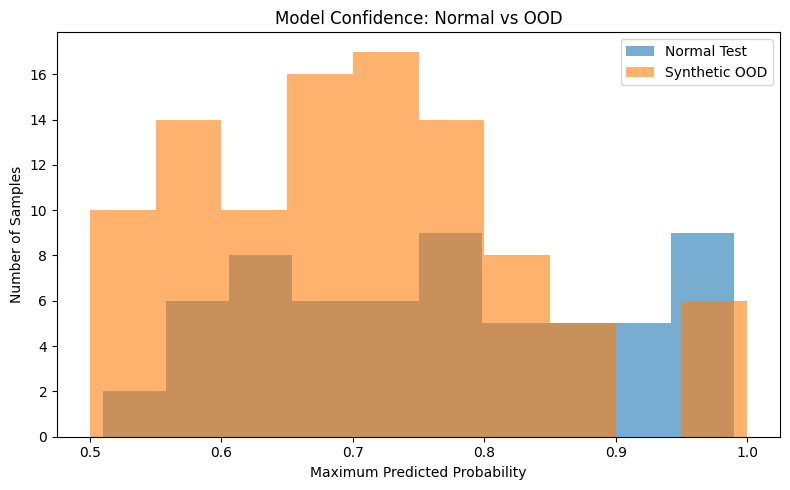

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(normal_confidence, bins=10, alpha=0.6, label="Normal Test")
plt.hist(ood_confidence, bins=10, alpha=0.6, label="Synthetic OOD")

plt.xlabel("Maximum Predicted Probability")
plt.ylabel("Number of Samples")
plt.title("Model Confidence: Normal vs OOD")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
ood_review = ood_samples.copy()
ood_review["Predicted_Class"] = ood_predictions
ood_review["Confidence"] = ood_confidence
ood_review["High_Confidence"] = ood_confidence >= 0.90

display(
    ood_review.sort_values("Confidence", ascending=False).head(10)
)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Predicted_Class,Confidence,High_Confidence
90,55.128080,1,0,153.569321,319.624020,0,0,90.753902,1,1.667941,1,2,3,0,1.00,True
87,55.169887,1,0,143.820620,300.006454,0,0,104.174092,1,1.295431,1,2,3,0,0.99,True
26,48.981500,1,2,133.572979,116.565186,1,1,195.952185,0,-0.464970,2,0,2,1,0.98,True
65,44.576503,0,2,139.409273,234.080868,1,1,128.380634,0,-1.159622,2,0,2,1,0.95,True
93,41.311411,1,0,140.001199,339.376148,0,0,85.254720,1,2.268471,1,2,2,0,0.95,True
22,51.607330,1,0,154.952721,190.936732,1,1,142.397626,0,2.366999,1,2,3,0,0.95,True
72,49.989335,1,0,132.968303,312.757329,0,0,82.897347,1,1.774445,2,0,3,0,0.89,False
62,52.862816,0,1,117.520905,147.431055,0,1,215.333815,0,-1.550000,2,2,2,1,0.88,False
56,71.513870,0,2,86.788742,236.519218,1,1,72.241047,0,-1.550000,2,0,2,1,0.87,False
39,66.010030,1,0,128.213853,329.590206,0,1,162.167738,1,1.199338,1,1,3,0,0.87,False
